In [1]:
import numpy as np
import pandas as pd

import torch
import torch.nn as nn

DEVICE = "mps"
SEED = 43

## exercise2-3, A residual neural network

In [2]:
class ResnetBlock(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(8,8)
        self.layer2 = nn.Linear(8,8)
 
    def forward(self, x):
        identity = x
        out = self.layer1(x)
        out = self.layer2(out)
        return identity + out
    
class AssembleBlock(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2,8),
            nn.LeakyReLU(),
            ResnetBlock(), # torch will automatically do the forward()
            nn.LeakyReLU(),
            nn.Linear(8,1),
        )

    def forward(self, x):
        return self.net(x)

In [3]:
'''
Download the concentric.csv dataset (it is the same from that
demonstration) and import it and separate out the variables
“[’X0’,’X1’]” and the label “label”. Copy the “standard setup and
loop” from intro to pytorch.ipynb, and compare your result to
that of the demonstration.
'''

'\nDownload the concentric.csv dataset (it is the same from that\ndemonstration) and import it and separate out the variables\n“[’X0’,’X1’]” and the label “label”. Copy the “standard setup and\nloop” from intro to pytorch.ipynb, and compare your result to\nthat of the demonstration.\n'

In [4]:
df = pd.read_csv("/Users/fangsiyu/Desktop/SDU-2026-fall-code/DL/concentric.csv")
df

,X0,X1,label
0,0.754246,0.231481,1
1,-0.756159,0.153259,1
2,-0.815392,0.173282,1
3,-0.393731,0.692883,1
4,0.442208,-0.896723,0
...,...,...,...
995,0.244054,0.944125,0
996,-0.978655,-0.272373,0
997,-0.136900,-0.810012,1
998,0.670362,-0.767502,0


In [5]:
# for splitting

from torch.utils.data import TensorDataset, random_split, DataLoader

X = torch.tensor(df[['X0','X1']].values, dtype=torch.float32).to(DEVICE)
y = torch.tensor(df['label'].values, dtype=torch.float32).to(DEVICE)

print(f"X: {X.size()}\ny: {y.size()}")



dataset = TensorDataset(X, y)

g = torch.Generator().manual_seed(SEED)
train_set, val_set, test_set = random_split(dataset, [0.7, 0.15, 0.15], generator=g)

train_loader = DataLoader(train_set, batch_size=32, shuffle=True) # batch_size=len(train_set)
val_loader   = DataLoader(val_set, batch_size=32)
test_loader  = DataLoader(test_set, batch_size=32)


X: torch.Size([1000, 2])
y: torch.Size([1000])


In [6]:
def accuracy(y_true, y_pred):
    return (y_true == y_pred).float().sum() / y_true.size(0) * 100

model = AssembleBlock().to(DEVICE)

loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [7]:
model.train()

for epoch in range(1000):
    for t_x, t_y in train_loader:

        logits = model(t_x).squeeze(1)

        loss = loss_fn(logits, t_y)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    # if epoch % 100 == 0:
    #         acc = accuracy(t_y, torch.round(torch.sigmoid(logits)))
    #         print(f"Epoch {epoch:<4} | loss={loss.item():.4f} | accuracy={acc.item():.2f}")

    if epoch % 100 == 0 or epoch == 1000 :
        with torch.no_grad():
            x_tr, y_tr = X[train_set.indices], y[train_set.indices]
            logits_tr = model(x_tr).squeeze(1)
            loss_tr = loss_fn(logits_tr, y_tr)
            acc = accuracy(y_tr, torch.round(torch.sigmoid(logits_tr)))
        print(f"Epoch {epoch:<4} | loss={loss_tr.item():.4f} | accuracy={acc.item():.2f}")

Epoch 0    | loss=0.7002 | accuracy=49.00
Epoch 100  | loss=0.0602 | accuracy=98.86
Epoch 200  | loss=0.0097 | accuracy=99.86
Epoch 300  | loss=0.0023 | accuracy=100.00
Epoch 400  | loss=0.0008 | accuracy=100.00
Epoch 500  | loss=0.0003 | accuracy=100.00
Epoch 600  | loss=0.0001 | accuracy=100.00
Epoch 700  | loss=0.0001 | accuracy=100.00
Epoch 800  | loss=0.0001 | accuracy=100.00
Epoch 900  | loss=0.0000 | accuracy=100.00


In [8]:
## Evaluation
# this structure will not use the batch for accuracy

X_val, y_val = X[val_set.indices], y[val_set.indices]

model.eval()

with torch.no_grad():
    val_logits = model(X_val).squeeze(1)
    val_loss = loss_fn(val_logits, y_val)
    val_acc = accuracy(y_val, torch.round(torch.sigmoid(val_logits)))
    print(f"Val loss: {val_loss.item():.4f} | Val accuracy: {val_acc.item():.2f}")

Val loss: 0.0059 | Val accuracy: 100.00


In [9]:
## test
# this structure will not use the batch for accuracy

X_test, y_test = X[test_set.indices], y[test_set.indices]

model.eval()

with torch.no_grad():
    test_logits = model(X_test).squeeze(1)
    test_loss = loss_fn(test_logits, y_test)
    test_acc = accuracy(y_test, torch.round(torch.sigmoid(test_logits)))
    print(f"Val loss: {test_loss.item():.4f} | Val accuracy: {test_acc.item():.2f}")

Val loss: 0.0031 | Val accuracy: 100.00


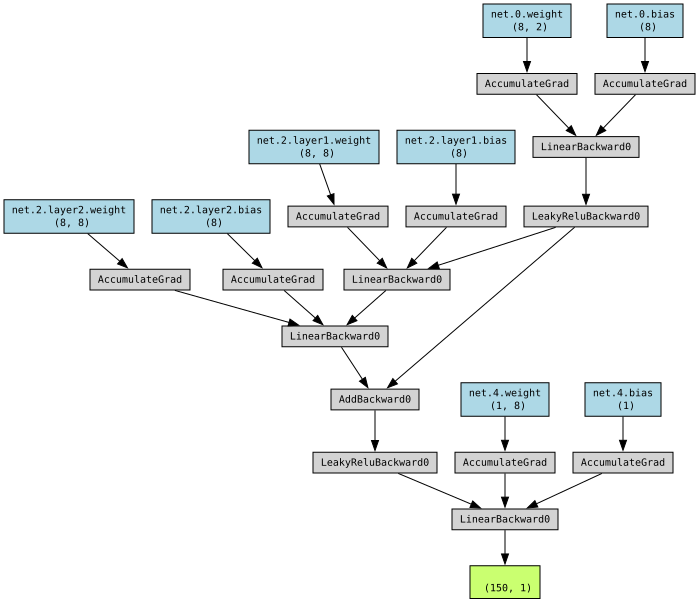

In [10]:
from torchviz import make_dot

make_dot(model(X_test), params=dict(
list(model.named_parameters())))